# 04 · So sánh bốn cấu hình trên đánh giá bán tổng hợp

> Đọc kết quả của run (`metrics_by_type.csv`, `paired_scores.csv`, điểm gốc/mutant). **Không fit lại.**

**Câu hỏi chính.** Biểu diễn đồ thị có bổ sung giá trị so với thống kê quy trình (A) và unigram/bigram (B) không?

**Nhắc về nghĩa của số liệu.**
- Nhãn `is_injected` = 1 là *mutant cấu trúc do ta chèn*, không phải bất thường thật; tỷ lệ 0,5 là tỷ lệ **thiết kế**.
- Đây là đánh giá bán tổng hợp, **không** phải ‘độ chính xác phát hiện lỗi thực tế’.
- `validation` chỉ để kiểm tra/chọn cấu hình; `test` là holdout, báo riêng.

In [1]:
# Khởi tạo: mở run đã kiểm fingerprint (biến môi trường JIRA_AD_RUN_DIR do `jira-ad notebooks` đặt).
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from jira_ad.analysis import open_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 90
run = open_run()
print(run.header())

run_id      : 20261017T081309Z-930f8a85  (status: completed)
chọn run    : tự động: run hoàn tất mới nhất khớp configs/baseline.yaml hiện tại (đặt JIRA_AD_RUN_DIR để chọn run khác)
config_hash : 930f8a856d4a…  config: configs/experiments.yaml
split_hash  : a3999ae50439…  action_rules: 4a35ef7d0f48…
đầu vào     : dataset/TIeventlogBug.csv sha256=cda16f1c5c4a…; configs/actions.yaml sha256=4a35ef7d0f48…
seeds       : {'split': 42, 'model': 42, 'validation_mutation': 1042, 'test_mutation': 2042}  | cohort: bug  | methods: ['A_stats', 'B_ngrams', 'C_embedding', 'D_hybrid']


In [2]:
from jira_ad import plots

metrics = run.read_csv("metrics_by_type.csv")
paired = run.read_csv("paired_scores.csv")
originals = run.read_parquet("scores/originals.parquet")
mutants = run.read_parquet("scores/mutants.parquet")
ledger = run.read_csv("mutation_ledger.csv")
summary = run.read_csv("tables/model_summary.csv")
test, validation = metrics[metrics.split == "test"], metrics[metrics.split == "validation"]
methods = run.methods

## 1. Giao thức và cỡ mẫu

In [3]:
protocol = (ledger.groupby(["split", "mutation_type"])
            .agg(parents=("parent_case_id", "nunique"), created=("status", lambda s: int((s == "created").sum())),
                 skipped=("status", lambda s: int((s == "skipped").sum())))
            .reset_index())
run.save_table(protocol, "nb04_protocol")
display(protocol)
display(Markdown(
    f"Seeds: split {run.manifest['seeds']['split']}, model {run.manifest['seeds']['model']}, mutation validation/test "
    f"{run.manifest['seeds']['validation_mutation']}/{run.manifest['seeds']['test_mutation']}. Mỗi benchmark theo loại dùng một bản gốc và một mutant "
    "cho mỗi parent có mutant hợp lệ (tỷ lệ thiết kế 0,5; AP của bộ dự đoán hằng = 0,5); các phương pháp so trên cùng tập parent. "
    "Một model seed duy nhất ⇒ chưa đo được độ ổn định theo seed."
))

,split,mutation_type,parents,created,skipped
0,test,delete_internal,31,31,0
1,test,duplicate_block,31,31,0
2,test,swap_adjacent,31,31,0
3,validation,delete_internal,33,33,0
4,validation,duplicate_block,33,33,0
5,validation,swap_adjacent,33,33,0


Seeds: split 42, model 42, mutation validation/test 1042/2042. Mỗi benchmark theo loại dùng một bản gốc và một mutant cho mỗi parent có mutant hợp lệ (tỷ lệ thiết kế 0,5; AP của bộ dự đoán hằng = 0,5); các phương pháp so trên cùng tập parent. Một model seed duy nhất ⇒ chưa đo được độ ổn định theo seed.

## 2. Kết quả trên test (holdout)

In [4]:
def pivot(frame, column):
    return frame.pivot(index="method", columns="mutation_type", values=column).reindex(methods)

n_table = test.groupby("mutation_type").n_mutant.first().to_frame("n parent/mutant").T
tables = {name: pivot(test, col) for name, col in [("AUROC", "auroc"), ("Average Precision", "average_precision"),
                                                    ("Paired win rate", "paired_win_rate")]}
for name, table in tables.items():
    table = table.assign(macro=table.mean(axis=1))
    run.save_table(table.reset_index(), "nb04_test_" + name.lower().replace(" ", "_"))
    display(Markdown(f"**{name} (test)**"))
    display(table)
display(n_table)

**AUROC (test)**

mutation_type,delete_internal,duplicate_block,swap_adjacent,macro
method,,,,
A_stats,0.511,0.554,0.518,0.527
B_ngrams,0.513,0.519,0.524,0.519
C_embedding,0.559,0.524,0.500,0.528
D_hybrid,0.568,0.554,0.514,0.545


**Average Precision (test)**

mutation_type,delete_internal,duplicate_block,swap_adjacent,macro
method,,,,
A_stats,0.521,0.531,0.531,0.528
B_ngrams,0.539,0.537,0.533,0.536
C_embedding,0.558,0.541,0.500,0.533
D_hybrid,0.593,0.577,0.524,0.565


**Paired win rate (test)**

mutation_type,delete_internal,duplicate_block,swap_adjacent,macro
method,,,,
A_stats,0.516,0.645,0.565,0.575
B_ngrams,0.645,0.645,0.694,0.661
C_embedding,0.710,0.613,0.500,0.608
D_hybrid,0.742,0.774,0.565,0.694


mutation_type,delete_internal,duplicate_block,swap_adjacent
n parent/mutant,31,31,31


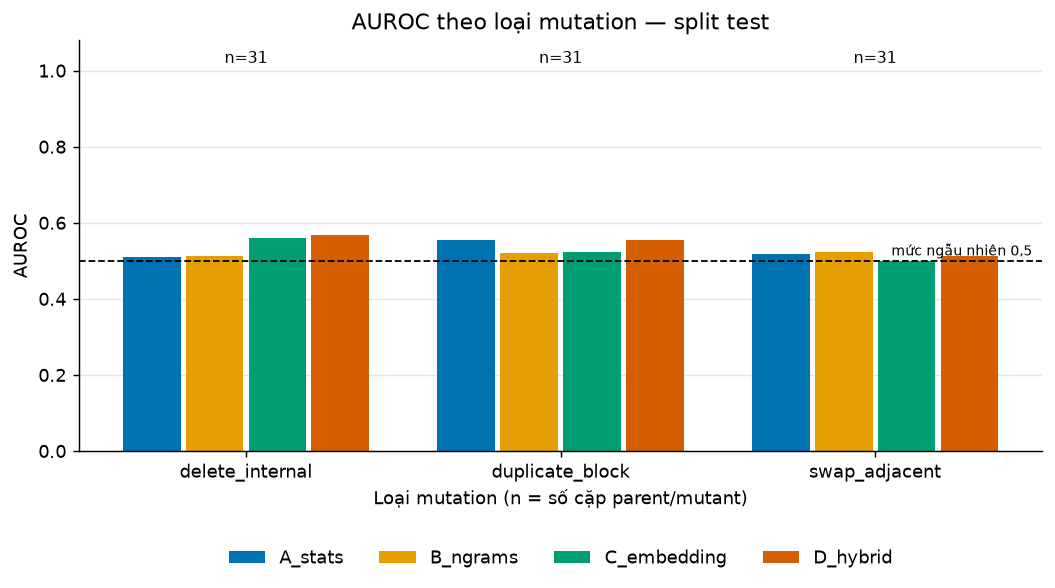

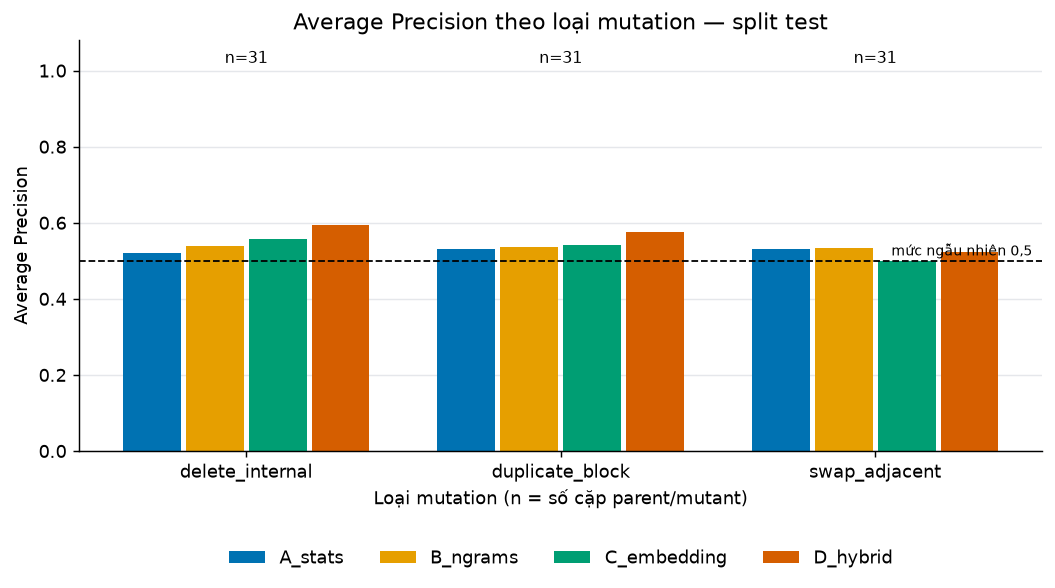

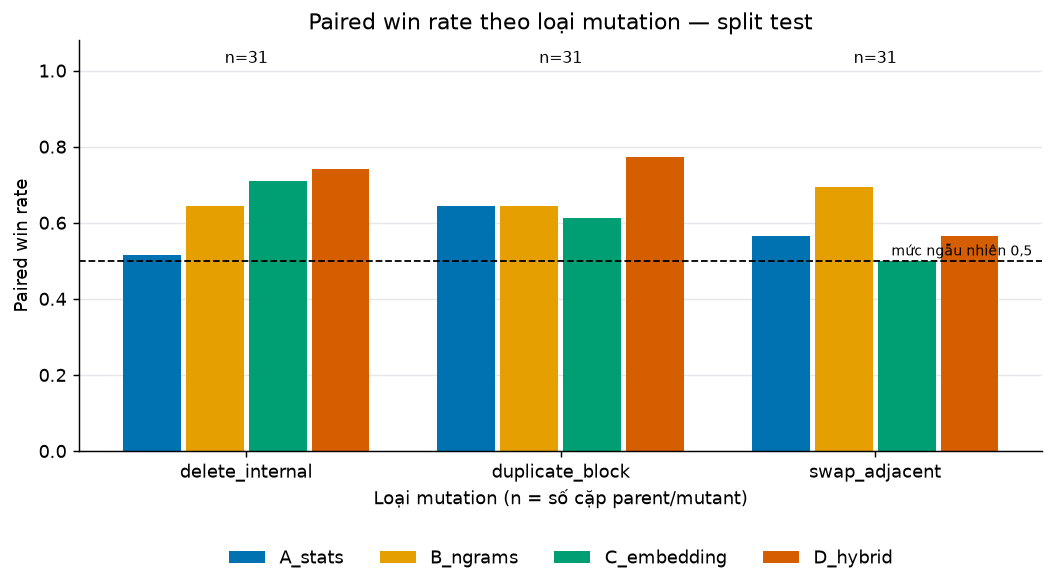

In [5]:
for metric, name in [("auroc", "nb04_test_auroc"), ("average_precision", "nb04_test_ap"), ("paired_win_rate", "nb04_test_paired_win")]:
    fig = plots.plot_metric_by_type(test, metric, split="test")
    _ = run.show(fig, name, test[["method", "mutation_type", "n_mutant", metric]])

## 3. Nhiễu lấy mẫu: công thức giải tích cho hai mẫu độc lập (chỉ để đối chiếu)

> **Cảnh báo.** Sai số chuẩn Hanley–McNeil/Mann–Whitney dưới đây giả định bản gốc và mutant là **hai mẫu độc lập**. Ở đây mỗi mutant được sinh từ chính một bản gốc,
> nên dữ liệu là **ghép cặp** và phương sai giữa các parent bị triệt tiêu khi so cặp. Khoảng này vì vậy **quá rộng** (bảo thủ) cho thiết kế này; mục 3b (bootstrap theo parent và
> thử hoán vị trong cặp) mới là chuẩn so sánh đúng. Các phiên bản trước của đồ án dùng con số này để kết luận “mọi AUROC chứa 0,5”; kết luận đó đã được sửa ở mục 3b.

In [6]:
def hanley_mcneil_se(auc, n_pos, n_neg):
    """Sai số chuẩn xấp xỉ của AUROC (Hanley & McNeil, 1982)."""
    q1, q2 = auc / (2 - auc), 2 * auc ** 2 / (1 + auc)
    var = (auc * (1 - auc) + (n_pos - 1) * (q1 - auc ** 2) + (n_neg - 1) * (q2 - auc ** 2)) / (n_pos * n_neg)
    return float(np.sqrt(var))

def wilson(wins, n, z=1.96):
    p = wins / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

noise = test.copy()
noise["auroc_se"] = [hanley_mcneil_se(r.auroc, r.n_mutant, r.n_original) for r in noise.itertuples()]
noise["auroc_lo"] = noise.auroc - 1.96 * noise.auroc_se
noise["auroc_hi"] = noise.auroc + 1.96 * noise.auroc_se
ci = [wilson(round(r.paired_win_rate * r.n_mutant), r.n_mutant) for r in noise.itertuples()]
noise["win_lo"], noise["win_hi"] = [c[0] for c in ci], [c[1] for c in ci]
noise["auroc_ci_contains_0.5"] = (noise.auroc_lo <= 0.5) & (noise.auroc_hi >= 0.5)
noise["win_ci_contains_0.5"] = (noise.win_lo <= 0.5) & (noise.win_hi >= 0.5)
run.save_table(noise[["method", "mutation_type", "n_mutant", "auroc", "auroc_lo", "auroc_hi", "paired_win_rate",
                      "win_lo", "win_hi", "auroc_ci_contains_0.5", "win_ci_contains_0.5"]], "nb04_noise")
noise[["method", "mutation_type", "auroc", "auroc_lo", "auroc_hi", "paired_win_rate", "win_lo", "win_hi"]]

,method,mutation_type,auroc,auroc_lo,auroc_hi,paired_win_rate,win_lo,win_hi
12,A_stats,delete_internal,0.511,0.366,0.656,0.516,0.348,0.680
13,B_ngrams,delete_internal,0.513,0.368,0.658,0.645,0.469,0.789
14,C_embedding,delete_internal,0.559,0.415,0.702,0.710,0.534,0.839
15,D_hybrid,delete_internal,0.568,0.425,0.711,0.742,0.568,0.863
16,A_stats,duplicate_block,0.554,0.410,0.697,0.645,0.469,0.789
17,B_ngrams,duplicate_block,0.519,0.375,0.664,0.645,0.469,0.789
18,C_embedding,duplicate_block,0.524,0.380,0.669,0.613,0.438,0.763
19,D_hybrid,duplicate_block,0.554,0.410,0.697,0.774,0.602,0.886
20,A_stats,swap_adjacent,0.518,0.373,0.662,0.565,0.408,0.736
21,B_ngrams,swap_adjacent,0.524,0.379,0.669,0.694,0.534,0.839


In [7]:
macro = test.groupby("method")[["auroc", "average_precision", "paired_win_rate"]].mean().reindex(methods)
best = macro.auroc.idxmax()
se_macro = float(np.mean([hanley_mcneil_se(r.auroc, r.n_mutant, r.n_original) for r in test.itertuples()])) / np.sqrt(test.mutation_type.nunique())
display(Markdown(
    f"- Macro AUROC cao nhất: **{best}** ({macro.auroc[best]:.3f}); thấp nhất {macro.auroc.min():.3f}. "
    f"Chênh lệch lớn nhất giữa các phương pháp: **{macro.auroc.max() - macro.auroc.min():.3f}**, trong khi sai số chuẩn theo công thức hai mẫu độc lập (quá rộng cho dữ liệu ghép cặp) của "
    f"một AUROC đơn lẻ ở n={int(test.n_mutant.min())} là **{noise.auroc_se.mean():.3f}**.\n"
    f"- **{int(noise['auroc_ci_contains_0.5'].sum())}/{len(noise)}** ô (phương pháp × loại) có khoảng tin cậy 95% xấp xỉ (hai mẫu độc lập) của AUROC chứa 0,5; "
    f"**{int(noise['win_ci_contains_0.5'].sum())}/{len(noise)}** ô có khoảng Wilson của paired win rate chứa 0,5."
))

- Macro AUROC cao nhất: **D_hybrid** (0.545); thấp nhất 0.519. Chênh lệch lớn nhất giữa các phương pháp: **0.026**, trong khi sai số chuẩn theo công thức hai mẫu độc lập (quá rộng cho dữ liệu ghép cặp) của một AUROC đơn lẻ ở n=31 là **0.074**.
- **12/12** ô (phương pháp × loại) có khoảng tin cậy 95% xấp xỉ (hai mẫu độc lập) của AUROC chứa 0,5; **8/12** ô có khoảng Wilson của paired win rate chứa 0,5.

## 3b. Khoảng tin cậy bootstrap theo parent

Khoảng ở mục 3 là xấp xỉ giải tích. Ở đây dùng **bootstrap theo `parent_case_id`**: resample có hoàn lại các parent, mang theo bản gốc và mọi bản con của parent đó.
Mọi phương pháp và mọi loại mutation dùng **chung một lần resample**, nên chênh lệch giữa hai phương pháp là chênh lệch *ghép cặp*.
Khoảng này đo độ bất định do **chọn ca**; nó không phải độ bất định theo model seed (xem mục 6) và không biến tỷ lệ thiết kế 0,5 thành tỷ lệ bất thường thực tế.

In [8]:
has_boot = all((run.run_dir / f).is_file()
               for f in ("bootstrap_intervals.csv", "bootstrap_differences.csv", "positive_control.csv", "chance_test.csv"))
vs_ref = None
se_ref = float(noise.auroc_se.mean())
se_ref_label = "công thức hai mẫu độc lập"
if not has_boot:
    display(Markdown("**Run này được tạo trước khi pipeline ghi bootstrap và đối chứng dương.** Tạo lại bằng: `"
                     + run.manifest["rerun_command"] + "`"))
else:
    intervals = run.read_csv("bootstrap_intervals.csv")
    differences = run.read_csv("bootstrap_differences.csv")
    boot_meta = run.read_json("metrics.json")["bootstrap"]["test"]
    macro_ci = (intervals[(intervals.split == "test") & (intervals.scope == "macro") & (intervals.metric == "auroc")]
                .set_index("method").reindex(methods))
    run.save_table(macro_ci.reset_index(), "nb04_bootstrap_macro_auroc")
    display(Markdown(f"**Macro AUROC (test)** — bootstrap {boot_meta['n_resamples']} lần theo `{boot_meta['unit']}`, "
                     f"khoảng {boot_meta['confidence']:.0%}, {boot_meta['n_parents']} parent"))
    display(macro_ci[["estimate", "ci_low", "ci_high", "se"]])

    chance_all = run.read_csv("chance_test.csv")
    chance_test = chance_all[chance_all.split == "test"]
    run.save_table(chance_test, "nb04_chance_test")
    null_sd = chance_test.groupby("method").null_sd.mean().reindex(methods)
    p_table = chance_test.pivot(index="method", columns="scope", values="p_value").reindex(methods)
    n_perm = int(chance_test.n_permutations.iloc[0])
    display(Markdown(
        f"**Thử hoán vị trong cặp (test) — p-value một phía của AUROC so với 0,5**, {n_perm} hoán vị. Giả thuyết không: với mỗi parent, bản gốc và mutant cùng phân phối. "
        "Không hiệu chỉnh đa so sánh."))
    display(p_table.assign(**{"SD của AUROC dưới H0 (trung bình)": null_sd}))
    display(Markdown(
        f"SD của AUROC dưới giả thuyết không *ghép cặp* ≈ **{null_sd.mean():.3f}**, nhỏ hơn nhiều so với {noise.auroc_se.mean():.3f} theo công thức hai mẫu độc lập ở mục 3: "
        "đó là lý do khoảng ở mục 3 quá rộng."))

    reference = "A_stats" if "A_stats" in methods else methods[0]
    pairs = differences[(differences.split == "test") & (differences.scope == "macro") & (differences.metric == "auroc")]
    rows = []
    for m in methods:
        if m == reference:
            continue
        direct = pairs[(pairs.method_a == m) & (pairs.method_b == reference)]
        if len(direct):
            r = direct.iloc[0]
            est, lo, hi, prob = r.estimate, r.ci_low, r.ci_high, r.prob_positive
        else:  # cặp được lưu theo chiều ngược lại: đảo dấu
            r = pairs[(pairs.method_a == reference) & (pairs.method_b == m)].iloc[0]
            est, lo, hi, prob = -r.estimate, -r.ci_high, -r.ci_low, 1 - r.prob_positive
        rows.append({"method": m, "so với": reference, "Δ macro AUROC": est, "ci_low": lo, "ci_high": hi,
                     "P(Δ>0)": prob, "khoảng chứa 0": bool(lo <= 0 <= hi)})
    vs_ref = pd.DataFrame(rows).set_index("method")
    run.save_table(vs_ref.reset_index(), "nb04_bootstrap_vs_reference")
    display(Markdown(f"**Chênh lệch macro AUROC so với `{reference}` (test), ghép cặp theo parent** — "
                     "câu hỏi chính: biểu diễn đồ thị có hơn thống kê quy trình không?"))
    display(vs_ref)
    se_ref, se_ref_label = float(macro_ci.se.mean()), "bootstrap theo parent"

**Macro AUROC (test)** — bootstrap 2000 lần theo `parent_case_id`, khoảng 95%, 31 parent

,estimate,ci_low,ci_high,se
method,,,,
A_stats,0.527,0.494,0.566,0.019
B_ngrams,0.519,0.497,0.549,0.013
C_embedding,0.528,0.507,0.555,0.012
D_hybrid,0.545,0.526,0.576,0.012


**Thử hoán vị trong cặp (test) — p-value một phía của AUROC so với 0,5**, 2000 hoán vị. Giả thuyết không: với mỗi parent, bản gốc và mutant cùng phân phối. Không hiệu chỉnh đa so sánh.

scope,delete_internal,duplicate_block,swap_adjacent,SD của AUROC dưới H0 (trung bình)
method,,,,
A_stats,0.268,0.028,0.145,0.020
B_ngrams,0.242,0.111,0.063,0.016
C_embedding,0.001,0.021,1.000,0.011
D_hybrid,0.001,0.001,0.088,0.017


SD của AUROC dưới giả thuyết không *ghép cặp* ≈ **0.016**, nhỏ hơn nhiều so với 0.074 theo công thức hai mẫu độc lập ở mục 3: đó là lý do khoảng ở mục 3 quá rộng.

**Chênh lệch macro AUROC so với `A_stats` (test), ghép cặp theo parent** — câu hỏi chính: biểu diễn đồ thị có hơn thống kê quy trình không?

,so với,Δ macro AUROC,ci_low,ci_high,P(Δ>0),khoảng chứa 0
method,,,,,,
B_ngrams,A_stats,-0.009,-0.041,0.032,0.367,True
C_embedding,A_stats,0.000,-0.040,0.041,0.518,True
D_hybrid,A_stats,0.018,-0.015,0.057,0.883,True


## 3c. Đối chứng dương (chỉ validation)

Xáo ngẫu nhiên **toàn bộ** phần nội bộ của parent thuộc validation (giữ event đầu/cuối, giữ histogram và độ dài). Đây là sai lệch mạnh về thứ tự, dùng để **kiểm tra bộ máy**:
nếu một phương pháp nhạy với thứ tự mà vẫn không thấy gì ở đây thì pipeline có vấn đề. Nó không phải một loại mutation của V1, không chạy trên test và không dùng để chọn cấu hình.
`C_embedding` kỳ vọng ≈ 0,5 theo lý thuyết vì mean/max pooling không thấy thứ tự.

In [9]:
control = None
if has_boot:
    control = run.read_csv("positive_control.csv").set_index("method").reindex(methods)
    run.save_table(control.reset_index(), "nb04_positive_control")
    display(control[["n_original", "auroc", "auroc_ci_low", "auroc_ci_high", "average_precision",
                     "paired_win_rate", "null_reason"]])

,n_original,auroc,auroc_ci_low,auroc_ci_high,average_precision,paired_win_rate,null_reason
method,,,,,,,
A_stats,33,0.886,0.826,0.951,0.871,1.000,NaN
B_ngrams,33,0.527,0.448,0.614,0.524,0.606,NaN
C_embedding,33,0.500,0.500,0.500,0.500,0.500,NaN
D_hybrid,33,0.658,0.631,0.713,0.653,1.000,NaN


## 4. Thay đổi điểm theo từng parent

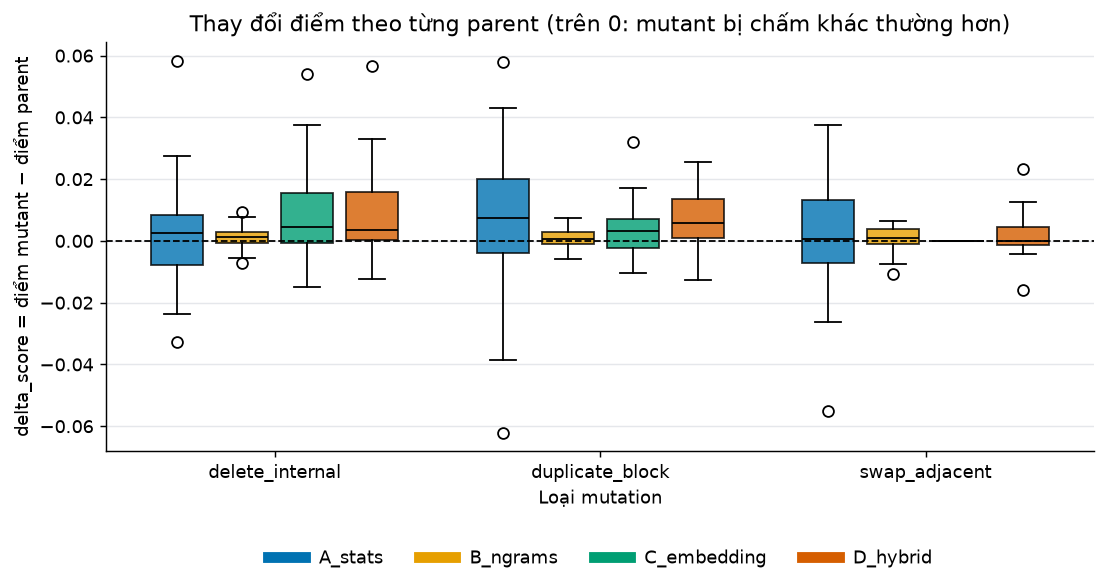

In [10]:
paired_test = paired[paired.split == "test"]
fig = plots.plot_paired_deltas(paired_test)
_ = run.show(fig, "nb04_paired_deltas", paired_test)

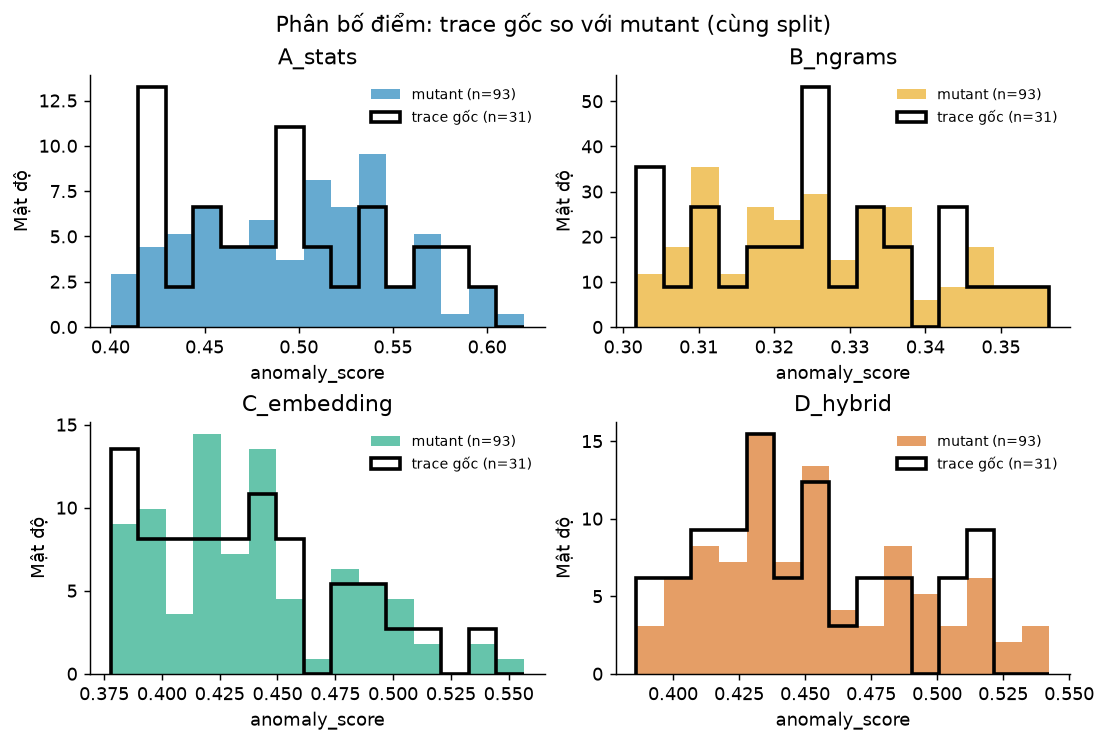

In [11]:
orig_test = originals[originals.split == "test"]
mut_test = mutants[mutants.split == "test"]
fig = plots.plot_score_distributions(orig_test, mut_test)
_ = run.show(fig, "nb04_score_distributions", pd.concat([orig_test.assign(kind="original"), mut_test.assign(kind="mutant")])[["method", "kind", "anomaly_score"]])

## 5. Tương quan với độ dài và chi phí

,"Spearman(điểm, n_events) trên trace gốc","Spearman(Δ độ dài, Δ điểm) trên mutant"
method,,
A_stats,-0.151,0.199
B_ngrams,0.558,0.016
C_embedding,-0.051,-0.136
D_hybrid,0.023,0.043


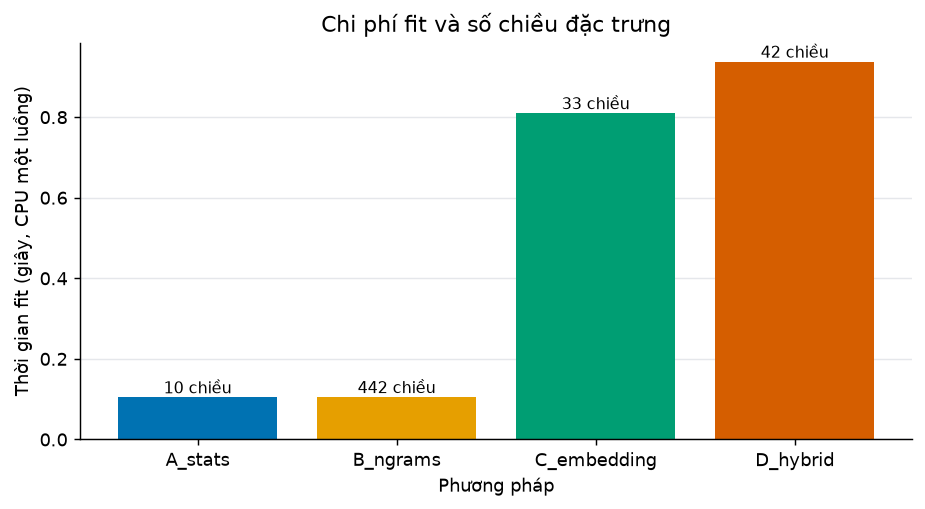

,method,n_features,n_constant_features,fit_seconds
0,A_stats,10,2,0.105
1,B_ngrams,442,2,0.106
2,C_embedding,33,2,0.810
3,D_hybrid,42,3,0.938


In [12]:
from scipy.stats import spearmanr

rows = []
for method in methods:
    o = orig_test[orig_test.method == method]
    rho_len = spearmanr(o.anomaly_score, o.n_events).statistic
    m = mut_test[mut_test.method == method].merge(o[["trace_id", "n_events", "anomaly_score"]],
                                                  left_on="parent_case_id", right_on="trace_id", suffixes=("", "_parent"))
    dlen = m.n_events - m.n_events_parent
    dscore = m.anomaly_score - m.anomaly_score_parent
    rho_delta = spearmanr(dlen, dscore).statistic if dlen.nunique() > 1 else float("nan")
    rows.append({"method": method, "Spearman(điểm, n_events) trên trace gốc": rho_len,
                 "Spearman(Δ độ dài, Δ điểm) trên mutant": rho_delta})
length_table = pd.DataFrame(rows).set_index("method")
run.save_table(length_table.reset_index(), "nb04_length_confound")
display(length_table)
runtime = summary.set_index("method").reindex(methods).reset_index()
fig = plots.plot_runtime(runtime)
_ = run.show(fig, "nb04_runtime", runtime)
display(runtime[["method", "n_features", "n_constant_features", "fit_seconds"]])

## 6. Ổn định theo model seed

In [13]:
import json
from jira_ad.analysis import run_macro_metrics
from jira_ad.pipeline import compare_runs

runs_dir = run.run_dir.parent
group = next(g for g in compare_runs(runs_dir)["groups"] if run.run_id in g["runs"])
macro_runs = run_macro_metrics(runs_dir, group["runs"], split="test")
seed_of = {rid: json.loads((runs_dir / rid / "manifest.json").read_text(encoding="utf-8"))["seeds"]["model"] for rid in group["runs"]}
macro_runs["model_seed"] = macro_runs.run_id.map(seed_of)
per_seed = macro_runs.pivot(index="method", columns="model_seed", values="macro_auroc").reindex(methods)
seed_summary = per_seed.assign(mean=per_seed.mean(axis=1), std=per_seed.std(axis=1, ddof=1) if per_seed.shape[1] > 1 else np.nan)
run.save_table(seed_summary.reset_index(), "nb04_seed_stability")
if per_seed.shape[1] < 2:
    display(Markdown("Nhóm của run này chỉ có một model seed ⇒ chưa đo được độ ổn định theo seed."))
else:
    display(seed_summary)
    display(Markdown(
        f"Macro AUROC (test) qua **{per_seed.shape[1]}** model seed (cùng split và cùng bộ mutant): độ lệch chuẩn theo seed lớn nhất **{seed_summary['std'].max():.3f}**, "
        f"so với SE của macro AUROC do chọn ca **{se_ref:.3f}** ({se_ref_label}). Đây là độ ổn định của bước học "
        "(Isolation Forest, walk, Skip-gram), **không** phải khoảng tin cậy quần thể và không phải nhiều mẫu dữ liệu độc lập."
    ))

model_seed,42,43,44,mean,std
method,,,,,
A_stats,0.527,0.539,0.527,0.531,0.007
B_ngrams,0.519,0.512,0.507,0.513,0.006
C_embedding,0.528,0.540,0.537,0.535,0.006
D_hybrid,0.545,0.539,0.547,0.544,0.004


Macro AUROC (test) qua **3** model seed (cùng split và cùng bộ mutant): độ lệch chuẩn theo seed lớn nhất **0.007**, so với SE của macro AUROC do chọn ca **0.014** (bootstrap theo parent). Đây là độ ổn định của bước học (Isolation Forest, walk, Skip-gram), **không** phải khoảng tin cậy quần thể và không phải nhiều mẫu dữ liệu độc lập.

### 6b. Bootstrap theo parent, trung bình các model seed

Mục 3b dùng điểm của riêng run này (một model seed). Ở đây mỗi phương pháp là **trung bình số liệu của các run theo model seed** trong *mỗi lần resample* (cùng một lần chọn parent cho mọi phương pháp và mọi seed),
nên khoảng tin cậy phản ánh việc chọn ca mà không coi model seed là mẫu độc lập. Báo cả validation và test; test chỉ để mô tả, validation là nơi chọn.

In [14]:
from jira_ad.evaluation import bootstrap_by_parent, bootstrap_differences_frame, bootstrap_intervals_frame

seed_avg = None
if has_boot:
    ev = run.cfg.evaluation
    seed_avg = {}
    for split_name in ("validation", "test"):
        frames, aggregate = [], {m: [] for m in methods}
        for rid in group["runs"]:
            table = pd.read_csv(runs_dir / rid / "paired_scores.csv")
            table = table[table["split"] == split_name]
            frames.append(table.assign(method=table["method"] + "|" + rid))
            for m in methods:
                aggregate[m].append(f"{m}|{rid}")
        result = bootstrap_by_parent(
            pd.concat(frames, ignore_index=True), methods=[x for members in aggregate.values() for x in members],
            n_resamples=ev.bootstrap_resamples, seed=ev.bootstrap_seed, confidence=ev.confidence, aggregate=aggregate)
        seed_avg[split_name] = (bootstrap_intervals_frame(result), bootstrap_differences_frame(result))
    macro_avg = pd.concat([
        seed_avg[s][0].query("scope == 'macro' and metric == 'auroc'").assign(split=s) for s in seed_avg
    ]).pivot(index="method", columns="split", values=["estimate", "ci_low", "ci_high"]).reindex(methods)
    run.save_table(macro_avg.reset_index(), "nb04_seed_avg_macro_ci")
    display(Markdown(f"**Macro AUROC trung bình {len(group['runs'])} model seed**, bootstrap {ev.bootstrap_resamples} lần theo parent, khoảng {ev.confidence:.0%}:"))
    display(macro_avg)
    diffs = pd.concat([
        seed_avg[s][1].query("scope == 'macro' and metric == 'auroc'").assign(split=s) for s in seed_avg
    ], ignore_index=True)
    diffs["khoảng chứa 0"] = (diffs.ci_low <= 0) & (diffs.ci_high >= 0)
    run.save_table(diffs, "nb04_seed_avg_differences")
    display(Markdown("**Chênh lệch ghép cặp** giữa các phương pháp (macro AUROC; `method_a` − `method_b`; chưa hiệu chỉnh đa so sánh):"))
    display(diffs[["split", "method_a", "method_b", "estimate", "ci_low", "ci_high", "prob_positive", "khoảng chứa 0"]])
else:
    display(Markdown("Cần artifact bootstrap của run (xem mục 3b)."))

**Macro AUROC trung bình 3 model seed**, bootstrap 2000 lần theo parent, khoảng 95%:

estimate            ci_low            ci_high           
split           test validation   test validation    test validation
method                                                              
A_stats        0.531      0.524  0.501      0.496   0.567      0.555
B_ngrams       0.513      0.500  0.492      0.479   0.536      0.517
C_embedding    0.535      0.547  0.515      0.522   0.563      0.581
D_hybrid       0.544      0.547  0.523      0.526   0.575      0.581

**Chênh lệch ghép cặp** giữa các phương pháp (macro AUROC; `method_a` − `method_b`; chưa hiệu chỉnh đa so sánh):

,split,method_a,method_b,estimate,ci_low,ci_high,prob_positive,khoảng chứa 0
0,validation,B_ngrams,A_stats,-0.024,-0.062,0.005,0.056,True
1,validation,C_embedding,A_stats,0.024,-0.011,0.062,0.898,True
2,validation,C_embedding,B_ngrams,0.047,0.020,0.085,0.999,False
3,validation,D_hybrid,A_stats,0.023,-0.004,0.056,0.955,True
4,validation,D_hybrid,B_ngrams,0.047,0.026,0.084,1.000,False
5,validation,D_hybrid,C_embedding,-0.000,-0.015,0.020,0.586,True
6,test,B_ngrams,A_stats,-0.019,-0.052,0.013,0.113,True
7,test,C_embedding,A_stats,0.004,-0.035,0.038,0.586,True
8,test,C_embedding,B_ngrams,0.022,-0.008,0.053,0.935,True
9,test,D_hybrid,A_stats,0.012,-0.015,0.040,0.838,True


## Nhận xét (sinh từ số liệu của run này)

In [15]:
if vs_ref is not None:
    reading = ("khác biệt so với A_stats không phân biệt được với 0 theo bootstrap ghép cặp (mục 3b)" if vs_ref["khoảng chứa 0"].all()
               else "có khác biệt so với A_stats nằm ngoài khoảng bootstrap — xem mục 3b")
else:
    reading = ("khác biệt giữa các phương pháp nằm trong nhiễu theo công thức hai mẫu độc lập (bảo thủ)" if macro.auroc.max() - macro.auroc.min() < 2 * noise.auroc_se.mean()
               else "có khác biệt vượt 2 sai số chuẩn, nhưng vẫn cần lặp qua nhiều model seed")
winner_pw = macro.paired_win_rate.idxmax()
lines = [
    f"- **Thứ hạng macro AUROC (test):** " + " > ".join(f"{m} {macro.auroc[m]:.3f}" for m in macro.auroc.sort_values(ascending=False).index) + f" — {reading}.",
    f"- **Paired win rate** cao nhất: {winner_pw} ({macro.paired_win_rate[winner_pw]:.3f}); thường cao hơn AUROC vì so từng parent với chính mutant của nó, "
    "không chịu phương sai giữa các parent.",
    f"- **Chênh với A_stats:** " + "; ".join(f"{m} {macro.auroc[m] - macro.auroc['A_stats']:+.3f}" for m in methods if m != "A_stats" and "A_stats" in macro.index) + " (AUROC macro).",
]
if vs_ref is not None:
    contains = vs_ref["khoảng chứa 0"]
    tail = (f" — cả {len(vs_ref)}/{len(vs_ref)} khoảng chứa 0, tức chênh lệch không phân biệt được với 0 ở cỡ mẫu này."
            if contains.all() else
            f" — có {int((~contains).sum())}/{len(vs_ref)} khoảng không chứa 0: {list(vs_ref.index[~contains])}.")
    lines.append(
        f"- **Bootstrap theo parent (test), so với `{reference}`:** "
        + "; ".join(f"{m} {r['Δ macro AUROC']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]" for m, r in vs_ref.iterrows())
        + tail)
if seed_avg is not None:
    allpairs = pd.concat([seed_avg[s][1].query("scope == 'macro' and metric == 'auroc'").assign(split=s) for s in seed_avg], ignore_index=True)
    parts = []
    for a, b in (("D_hybrid", "A_stats"), ("D_hybrid", "B_ngrams"), ("C_embedding", "B_ngrams")):
        for s in ("validation", "test"):
            row = allpairs[(allpairs.split == s) & (allpairs.method_a == a) & (allpairs.method_b == b)]
            if len(row):
                r = row.iloc[0]
                parts.append(f"{a} − {b} ({s}) {r.estimate:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]" + (" ✓" if r.ci_low > 0 or r.ci_high < 0 else ""))
    lines.append("- **Trung bình các model seed, bootstrap theo parent** (✓ = khoảng không chứa 0; chưa hiệu chỉnh đa so sánh): " + "; ".join(parts) + ".")
if has_boot:
    alpha = 0.05
    significant = chance_test[chance_test.p_value < alpha]
    survives = chance_test[chance_test.p_value < alpha / len(chance_test)]
    by_type = significant.groupby("scope").size().reindex(sorted(chance_test.scope.unique()), fill_value=0).to_dict()
    lines.append(
        f"- **Khác ngẫu nhiên không (test, thử hoán vị trong cặp, p < 0,05 một phía):** {len(significant)}/{len(chance_test)} ô (phương pháp × loại) — theo loại {by_type}; "
        f"sau hiệu chỉnh Bonferroni (p < {alpha / len(chance_test):.4f}) còn {len(survives)} ô: "
        + (", ".join(f"{r.method}/{r.scope}" for r in survives.itertuples()) if len(survives) else "không ô nào")
        + f". SD của AUROC dưới H0 ghép cặp ≈ {null_sd.mean():.3f} (so với {noise.auroc_se.mean():.3f} theo hai mẫu độc lập): macro AUROC {macro.auroc.min():.2f}–{macro.auroc.max():.2f} là hiệu ứng "
          "**rất nhỏ**, phát hiện được ở một số loại sai lệch chứ không ở mọi loại; đó là câu hỏi khác với việc một phương pháp tốt hơn phương pháp kia.")
if control is not None:
    detected = list(control.index[control.auroc_ci_low > 0.5])
    lines.append(
        "- **Đối chứng dương (validation):** AUROC " + ", ".join(f"{m} {control.auroc[m]:.3f}" for m in methods)
        + f"; phương pháp có cả khoảng bootstrap nằm trên 0,5: {detected or 'không có'} "
        "(`C_embedding` kỳ vọng ≈ 0,5 theo lý thuyết vì pooling không thấy thứ tự).")
lines += [
    f"- **Độ dài:** Spearman(điểm, n_events) lớn nhất theo trị tuyệt đối ở **{length_table.iloc[:, 0].abs().idxmax()}** "
    f"({length_table.iloc[:, 0].loc[length_table.iloc[:, 0].abs().idxmax()]:+.2f}) ⇒ đọc kết quả loại delete/duplicate cùng cảnh báo này.",
    f"- **Chi phí:** fit {summary.fit_seconds.min():.2f}–{summary.fit_seconds.max():.2f} s (CPU, một luồng); số chiều {summary.n_features.min()}–{summary.n_features.max()}.",
    ("- **Seed:** " + (f"std của macro AUROC qua {per_seed.shape[1]} model seed tối đa {seed_summary['std'].max():.3f}, so với SE bootstrap theo parent của macro AUROC {se_ref:.3f} ({se_ref_label}) ⇒ "
                      "hai nguồn nhiễu cùng cỡ: đọc thứ hạng giữa các phương pháp cần cả hai." if per_seed.shape[1] > 1
                      else "chỉ một model seed nên chưa đo được độ ổn định.")),
    "- **Không khẳng định** embedding có hay không bổ sung giá trị khi chỉ có hai split nhỏ và ba loại sai lệch tinh vi.",
]
display(Markdown("\n".join(lines)))

- **Thứ hạng macro AUROC (test):** D_hybrid 0.545 > C_embedding 0.528 > A_stats 0.527 > B_ngrams 0.519 — khác biệt so với A_stats không phân biệt được với 0 theo bootstrap ghép cặp (mục 3b).
- **Paired win rate** cao nhất: D_hybrid (0.694); thường cao hơn AUROC vì so từng parent với chính mutant của nó, không chịu phương sai giữa các parent.
- **Chênh với A_stats:** B_ngrams -0.009; C_embedding +0.000; D_hybrid +0.018 (AUROC macro).
- **Bootstrap theo parent (test), so với `A_stats`:** B_ngrams -0.009 [-0.041, +0.032]; C_embedding +0.000 [-0.040, +0.041]; D_hybrid +0.018 [-0.015, +0.057] — cả 3/3 khoảng chứa 0, tức chênh lệch không phân biệt được với 0 ở cỡ mẫu này.
- **Trung bình các model seed, bootstrap theo parent** (✓ = khoảng không chứa 0; chưa hiệu chỉnh đa so sánh): D_hybrid − A_stats (validation) +0.023 [-0.004, +0.056]; D_hybrid − A_stats (test) +0.012 [-0.015, +0.040]; D_hybrid − B_ngrams (validation) +0.047 [+0.026, +0.084] ✓; D_hybrid − B_ngrams (test) +0.031 [+0.005, +0.062] ✓; C_embedding − B_ngrams (validation) +0.047 [+0.020, +0.085] ✓; C_embedding − B_ngrams (test) +0.022 [-0.008, +0.053].
- **Khác ngẫu nhiên không (test, thử hoán vị trong cặp, p < 0,05 một phía):** 5/12 ô (phương pháp × loại) — theo loại {'delete_internal': 2, 'duplicate_block': 3, 'swap_adjacent': 0}; sau hiệu chỉnh Bonferroni (p < 0.0042) còn 3 ô: C_embedding/delete_internal, D_hybrid/delete_internal, D_hybrid/duplicate_block. SD của AUROC dưới H0 ghép cặp ≈ 0.016 (so với 0.074 theo hai mẫu độc lập): macro AUROC 0.52–0.55 là hiệu ứng **rất nhỏ**, phát hiện được ở một số loại sai lệch chứ không ở mọi loại; đó là câu hỏi khác với việc một phương pháp tốt hơn phương pháp kia.
- **Đối chứng dương (validation):** AUROC A_stats 0.886, B_ngrams 0.527, C_embedding 0.500, D_hybrid 0.658; phương pháp có cả khoảng bootstrap nằm trên 0,5: ['A_stats', 'D_hybrid'] (`C_embedding` kỳ vọng ≈ 0,5 theo lý thuyết vì pooling không thấy thứ tự).
- **Độ dài:** Spearman(điểm, n_events) lớn nhất theo trị tuyệt đối ở **B_ngrams** (+0.56) ⇒ đọc kết quả loại delete/duplicate cùng cảnh báo này.
- **Chi phí:** fit 0.10–0.94 s (CPU, một luồng); số chiều 10–442.
- **Seed:** std của macro AUROC qua 3 model seed tối đa 0.007, so với SE bootstrap theo parent của macro AUROC 0.014 (bootstrap theo parent) ⇒ hai nguồn nhiễu cùng cỡ: đọc thứ hạng giữa các phương pháp cần cả hai.
- **Không khẳng định** embedding có hay không bổ sung giá trị khi chỉ có hai split nhỏ và ba loại sai lệch tinh vi.

## Giả thuyết và giới hạn

- Mutant một chỉnh sửa rất tinh vi so với phương sai tự nhiên giữa các issue (độ dài, số lần revisit): AUROC thấp **không** có nghĩa pipeline hỏng — bảng đối chứng dương ở mục 3c cho biết
  phương pháp nào bắt được xáo trộn mạnh.
- **Đính chính:** các bản trước dùng công thức hai mẫu độc lập (SE ≈ 0,074) và kết luận “mọi AUROC chứa 0,5”. Với thiết kế ghép cặp, SD dưới giả thuyết không chỉ ≈ 0,01 (mục 3b), nên AUROC 0,52–0,55
  là hiệu ứng nhỏ nhưng khác 0,5. Chênh lệch *giữa các phương pháp* vẫn không phân biệt được với 0.
- Khoảng bootstrap ở mục 3b chỉ phản ánh việc chọn ca (31 parent); ba loại mutant dùng chung các parent nên macro không giảm nhiễu nhiều so với từng loại riêng lẻ. Mỗi p-value hoán vị
  là theo từng loại; chưa hiệu chỉnh đa so sánh.
- Hai giả thuyết về cross-fit đặc trưng train và về pooling làm loãng `D_hybrid` được kiểm riêng theo quy tắc khóa trước ở notebook 06 (mục 4b), không ở đây.
- Cấu hình được khóa trước khi xem test; mọi thay đổi thiết kế sau khi đã xem test phải được ghi là *khám phá*, không phải xác nhận.
- Không chọn cấu hình tốt nhất theo test rồi công bố như một holdout.